Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

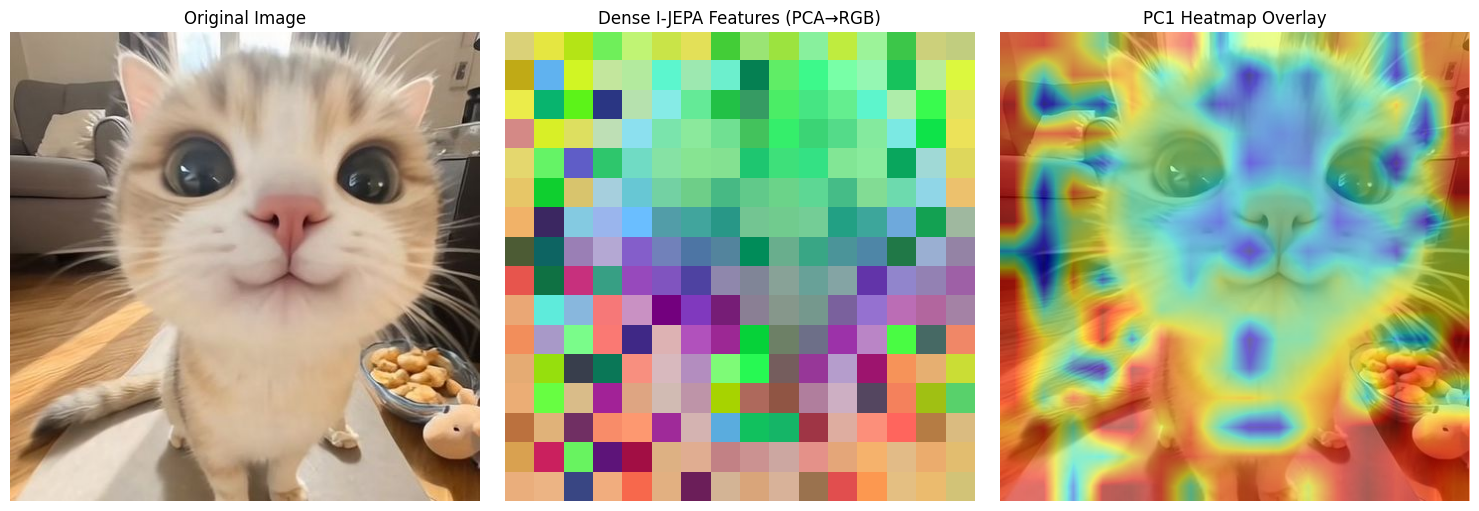

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoModel, AutoProcessor
from PIL import Image

# --- 1. Extract dense features with I-JEPA ---
model_name = "facebook/ijepa_vith14_1k"
model = AutoModel.from_pretrained(model_name).eval()
processor = AutoProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

last_hidden = outputs.last_hidden_state      # [B, seq_len, D]
B, seq_len, D = last_hidden.shape

# Derive actual grid from processed pixel values (robust to any resize/crop config)
pixel_values = inputs["pixel_values"]
_, _, H, W = pixel_values.shape
patch_size = model.config.patch_size
grid_h = H // patch_size
grid_w = W // patch_size
num_patches = grid_h * grid_w

# Only drop CLS if the sequence length indicates one is present
if seq_len == num_patches + 1:
    patch_tokens = last_hidden[:, 1:, :]     # drop CLS
elif seq_len == num_patches:
    patch_tokens = last_hidden               # all tokens are patches
else:
    raise ValueError(
        f"Unexpected seq_len {seq_len} for grid {grid_h}×{grid_w} ({num_patches} patches)"
    )

patch_tokens_np = patch_tokens[0].cpu().numpy()   # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)   # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_h, grid_w, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense I-JEPA Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_h, grid_w)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("ijepa_dense_features.png", dpi=150)
plt.show()